# Jensen Huang reinstated as NVIDIA CEO: who clicked first?

**Event:** NVIDIA's GlobeNewswire release, stamped *8:55 AM ET, 2026-11-23* (to the minute only).

**Question:** in the order-book tapes, when did takers start buying YES on "Jensen returns", which venue moved first, and was Hyperliquid's NVDA perp the trigger?

**Venues compared**

| Venue | What's public | Timestamp | Taker identity |
|---|---|---|---|
| Hyperliquid `xyz:NVDA`, `io:NVDA` | every fill (via Ironflow; S3 archive) | block time, ms | wallet |
| Kalshi | full trade tape (`/markets/trades`; older trades move to `/historical/trades`) | matching engine, µs | none |
| Polymarket (polymarket.com) | every taker fill (on-chain) | Polygon block, 1 s, lands ~1–3 s after the match | proxy wallet |
| Polymarket US | **no trade history.** Only ~1-minute book-derived display prices | minute | none |

Kalshi is *not* like Polymarket US: its tape is recoverable after the fact, so it sits next to Polymarket in every comparison below.

All pulls are cached in `data/2026-11-23-jensen/`, so the notebook re-runs offline. Times are ET (UTC−5).

In [1]:
%matplotlib inline
import sys, re, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from datetime import timezone, timedelta
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import hl, venues
from event_window import cached, ms

pd.set_option("display.max_rows", 200, "display.width", 200, "display.float_format", "{:,.4g}".format)
ET = timezone(timedelta(hours=-5))

START, END = ms("2026-11-23T13:54:00Z"), ms("2026-11-23T13:58:00Z")   # 8:54-8:58 ET
CACHE, TAG = ROOT / "data" / "2026-11-23-jensen", f"{START}-{END}"
MARKS = {"Press release minute": ms("2026-11-23T13:55:00Z"), "First X posts": ms("2026-11-23T13:55:51.5Z")}

HL_COINS = ["xyz:NVDA", "io:NVDA"]
KALSHI = {  # every Kalshi market that paid YES on Jensen's return
    "KXNVDACEO-29JAN-JENS": "K next CEO = Jensen",
    "KXJOINJENSENHUANG-27JAN-NVDA": "K next employer = Nvidia",
    "KXNVDACEOHIRE-29-29JAN01-JHUA": "K CEO hire = Jensen returns",
}
PM_EVENT = "jensen-huang-rejoins-nvidia-byptptpt"            # 4 dated "rejoin by" markets
PMUS = {"nphc-nvidiaceo-2028-12-31-jenhua": "US next CEO = Jensen", "nphc-jenhua-nvidiaceoby-2026-12-31": "US Jensen next CEO by 12/31"}

## 1. Load the tapes
One row per fill, aggressor side only. `side=+1` means the taker bought YES (or long on HL); `usd` is the taker's cash at risk (HL: notional).

In [2]:
def load(name, fetch):
    return pd.DataFrame(cached(CACHE / f"{name}-{TAG}.json", fetch))

parts = [load(f"hl-ironflow-{c.replace(':', '_')}", lambda c=c: hl.fills(c, START, END)) for c in HL_COINS]
parts += [load(f"kalshi-{t}", lambda t=t: venues.kalshi_trades(t, START, END)) for t in KALSHI]
parts.append(load(f"polymarket-{PM_EVENT}", lambda: venues.polymarket_trades(PM_EVENT, START, END)))
tape = pd.concat(parts, ignore_index=True).sort_values("t_ms", kind="stable").reset_index(drop=True)

def label(row):
    if row.venue == "kalshi":
        return KALSHI[row.market]
    if row.venue == "polymarket":
        return "PM rejoin by " + re.sub(r".*-by-", "", row.market)
    return "HL " + row.market
tape["label"] = tape.apply(label, axis=1)
tape["time"] = pd.to_datetime(tape.t_ms, unit="ms", utc=True).dt.tz_convert(ET)
tape["clock"] = tape.time.dt.strftime("%H:%M:%S.%f").str[:-3]

pmus = {s: load(f"pmus-{s}", lambda s=s: venues.pmus_prices(s, START, END)) for s in PMUS}

buys = tape[tape.side > 0]
tape.groupby(["venue", "label"]).agg(
    fills=("qty", "size"), yes_buy_qty=("qty", lambda q: q[tape.loc[q.index, "side"] > 0].sum()),
    yes_buy_usd=("usd", lambda u: u[tape.loc[u.index, "side"] > 0].sum()), first=("clock", "min"), last=("clock", "max"))

fills  yes_buy_qty  yes_buy_usd         first          last
venue       label                                                                                     
hyperliquid HL io:NVDA                      1217    2.358e+04    3.503e+06  08:54:04.836  08:57:59.431
            HL xyz:NVDA                    11535    4.851e+05    7.113e+07  08:54:00.023  08:57:59.966
kalshi      K CEO hire = Jensen returns       23    1.084e+04        1,856  08:55:57.906  08:57:59.393
            K next CEO = Jensen             1228    2.072e+06    8.557e+05  08:54:12.566  08:57:58.451
            K next employer = Nvidia         318     1.18e+05    3.147e+04  08:55:47.179  08:57:55.774
polymarket  PM rejoin by december-31-2026    134    2.291e+05    1.163e+05  08:54:50.000  08:57:59.000
            PM rejoin by december-31-2027    111    5.563e+04     3.11e+04  08:55:53.000  08:57:44.000
            PM rejoin by march-31-2027        63    1.457e+04        7,460  08:55:53.000  08:57:23.000
            PM rejoin by november-30-2026    185    2.268e+05    1.271e+05  08:54:14.000  08:57:53.000

## 2. First taker bursts per market
A *burst* is a bucket where YES/long taker buying reaches a venue-appropriate size. Thresholds differ because the instruments differ: HL is a $ perp, Kalshi and Polymarket are cents-per-contract and the nearest-dated Polymarket markets were 3–12¢ before the news.

In [3]:
RULES = {"hyperliquid": (500, 100_000), "kalshi": (500, 5_000), "polymarket": (1000, 2_000)}   # bucket ms, min $ per bucket

def bursts(df, bucket_ms, min_usd):
    b = df[df.side > 0].assign(bucket=lambda d: d.t_ms // bucket_ms)
    g = b.groupby("bucket").agg(clock=("clock", "first"), t_ms=("t_ms", "first"), qty=("qty", "sum"), usd=("usd", "sum"),
                                px_lo=("price", "min"), px_hi=("price", "max"))
    top = b.groupby(["bucket", "taker"]).usd.sum().reset_index().sort_values("usd").groupby("bucket").last()
    g["top_taker"] = top.taker.str[:10].replace("", "(anonymous)")
    g["top_share"] = top.usd / g.usd
    return g[g.usd >= min_usd].reset_index(drop=True)

burst_tables = {}
for (venue, lab), df in tape.groupby(["venue", "label"], sort=False):
    burst_tables[lab] = bursts(df, *RULES[venue]).assign(venue=venue, label=lab)
for lab, t in burst_tables.items():
    print(f"\n== {lab}")
    print(t.head(8)[["clock", "qty", "usd", "px_lo", "px_hi", "top_taker", "top_share"]].to_string(index=False))


== HL xyz:NVDA
       clock   qty       usd  px_lo  px_hi  top_taker  top_share
08:55:41.068 1,759 2.392e+05  135.9    136 0x25773676     0.9985
08:55:41.622 4,582 6.235e+05    136  136.1 0x0de52cf0     0.5612
08:55:42.022 3,186 4.336e+05  136.1  136.1 0x5234a0bb     0.6278
08:55:42.509 2,993 4.074e+05  136.1  136.2 0x0de52cf0     0.6573
08:55:43.027 3,272 4.456e+05  136.1  136.3 0x0de52cf0     0.5811
08:55:43.519 1,638 2.236e+05  136.3  136.6 0x0de52cf0     0.5517
08:55:44.047 1,354 1.851e+05  136.5  136.8 0x0de52cf0     0.6403
08:55:44.514 4,227 5.788e+05  136.8  137.2 0x21ba61c0     0.4631

== HL io:NVDA
       clock   qty       usd  px_lo  px_hi  top_taker  top_share
08:55:46.032 1,494 2.081e+05  137.6  139.7 0x25773676     0.9964
08:56:20.060   870 1.231e+05  140.5  148.3 0x6ec6711e     0.5784
08:56:23.666 685.6  1.04e+05  149.4    154 0x10990954     0.9896
08:56:45.401 1,369 1.942e+05  141.3  150.9 0x40000000     0.9316
08:56:57.053 981.2 1.425e+05  142.6    153 0x529a022b     0

## 3. Unified timeline
First burst on each market, with lags against the first Hyperliquid burst, the press-release minute, and the first X post.

In [4]:
first = pd.DataFrame([t.iloc[0] for t in burst_tables.values() if len(t)])[["venue", "label", "clock", "t_ms", "qty", "usd", "px_lo", "px_hi", "top_taker"]]
hl0 = first[first.venue == "hyperliquid"].t_ms.min()
first["vs_HL_s"] = (first.t_ms - hl0) / 1000
first["vs_release_s"] = (first.t_ms - MARKS["Press release minute"]) / 1000
first["vs_X_post_s"] = (first.t_ms - MARKS["First X posts"]) / 1000
first.sort_values("t_ms").drop(columns="t_ms").reset_index(drop=True)

,venue,label,clock,qty,usd,px_lo,px_hi,top_taker,vs_HL_s,vs_release_s,vs_X_post_s
0,hyperliquid,HL xyz:NVDA,08:55:41.068,"1,759",2.392e+05,135.9,136,0x25773676,0,41.07,-10.43
1,hyperliquid,HL io:NVDA,08:55:46.032,"1,494",2.081e+05,137.6,139.7,0x25773676,4.964,46.03,-5.468
2,kalshi,K next CEO = Jensen,08:55:48.399,2.802e+05,4.809e+04,0.17,0.18,(anonymous),7.331,48.4,-3.101
3,polymarket,PM rejoin by december-31-2026,08:55:53.000,5.098e+04,"6,329",0.1241,0.1241,0x3e03eaee,11.93,53,1.5
4,kalshi,K next employer = Nvidia,08:55:57.902,7.108e+04,"8,717",0.1,0.15,(anonymous),16.83,57.9,6.402
5,polymarket,PM rejoin by december-31-2027,08:56:04.000,"6,153","2,457",0.398,0.42,0x853c37a9,22.93,64,12.5
6,polymarket,PM rejoin by november-30-2026,08:56:14.000,2.924e+04,1.461e+04,0.4996,0.4996,0x3e03eaee,32.93,74,22.5
7,polymarket,PM rejoin by march-31-2027,08:56:43.000,"2,608","2,304",0.8835,0.8835,0x73e35ce0,61.93,103,51.5


**Reading it**
- Hyperliquid moved first. Polymarket's block times run ~1–3 s behind the actual match, so Polymarket's true first fill is a little earlier than shown; it is still after Kalshi's first burst.
- Kalshi's first burst (the 280k-contract print in the PM Pulse chart) landed while HL NVDA was already moving.
- Polymarket US can't be placed on this timeline at all: see section 7.

## 4. Kalshi vs Polymarket, side by side
YES taker flow per second from 8:55:40 to 8:56:40, and how much of the move each venue's early takers captured. Every one of these markets resolved YES at $1.

In [5]:
W0, W1 = ms("2026-11-23T13:55:40Z"), ms("2026-11-23T13:56:40Z")
pm_k = buys[buys.venue.isin(["kalshi", "polymarket"]) & buys.t_ms.between(W0, W1 - 1)].copy()
pm_k["group"] = np.where(pm_k.venue == "kalshi", pm_k.label, "PM rejoin (all 4 markets)")
pm_k["sec"] = pm_k.time.dt.floor("s").dt.strftime("%H:%M:%S")
per_sec = pm_k.pivot_table(index="sec", columns="group", values="usd", aggfunc="sum").fillna(0).round(0)
per_sec[per_sec.sum(axis=1) >= 1000]

group,K CEO hire = Jensen returns,K next CEO = Jensen,K next employer = Nvidia,PM rejoin (all 4 markets)
sec,,,,
08:55:48,0,4.809e+04,0,0
08:55:53,0,14,165,"6,395"
08:55:54,0,"1,832",0,0
08:55:55,0,0,5,"5,430"
08:55:56,0,0,1,"7,002"
08:55:57,"1,757",1.637e+04,"8,717",0
08:55:58,0,"1,309",93,57
08:56:01,0,0,0,"4,531"
08:56:03,0,4.78e+04,0,0


In [6]:
def edge(df):
    # Taker YES buys with profit at the $1 settlement.
    return pd.Series({"takers_$": df.usd.sum(), "contracts": df.qty.sum(), "vwap": df.usd.sum() / df.qty.sum(),
                      "payout_profit_$": (df.qty - df.usd).sum(), "fills": len(df)})

rows = {}
for lab, t in burst_tables.items():
    if not len(t) or t.venue.iloc[0] == "hyperliquid":
        continue
    t0 = t.t_ms.iloc[0]
    d = buys[buys.label == lab]
    for win in (15, 30, 60):
        rows[(lab, f"first {win}s")] = edge(d[d.t_ms.between(t0, t0 + win * 1000 - 1)])
pd.DataFrame(rows).T

takers_$  contracts   vwap  payout_profit_$  fills
K next CEO = Jensen           first 15s 1.154e+05  6.394e+05 0.1805         5.24e+05    108
                              first 30s 5.779e+05  1.696e+06 0.3408        1.118e+06    604
                              first 60s 6.743e+05  1.833e+06 0.3678        1.159e+06    812
PM rejoin by november-30-2026 first 15s 2.592e+04  5.186e+04 0.4998        2.594e+04     14
                              first 30s 2.914e+04  5.713e+04 0.5101        2.799e+04     27
                              first 60s 1.025e+05  1.336e+05 0.7671        3.112e+04     45
PM rejoin by december-31-2026 first 15s 2.062e+04  1.258e+05 0.1639        1.052e+05     23
                              first 30s 2.199e+04  1.286e+05 0.1709        1.066e+05     32
                              first 60s 2.617e+04  1.354e+05 0.1933        1.093e+05     65
K next employer = Nvidia      first 15s     9,234  7.373e+04 0.1253        6.449e+04     56
                              first 30s 1.186e+04  8.233e+04  0.144        7.047e+04    100
                              first 60s 1.971e+04  9.922e+04 0.1986        7.951e+04    180
PM rejoin by december-31-2027 first 15s 1.874e+04  3.987e+04 0.4701        2.113e+04     12
                              first 30s 1.951e+04  4.097e+04  0.476        2.147e+04     19
                              first 60s 2.494e+04  4.726e+04 0.5278        2.232e+04     52
PM rejoin by march-31-2027    first 15s     2,314      2,619 0.8836            304.8      2
                              first 30s     2,643      2,969 0.8902            325.9      4
                              first 60s     4,009      4,401 0.9108            392.4      7

Kalshi printed far more size in the first 30 s than any Polymarket market. Kalshi's next-CEO market started at 17¢; Polymarket's nearest-dated markets started cheaper (Nov-30 about 3¢, Dec-31-2026 about 12¢), but their books were thin: Nov-30 went from about 3¢ to 50¢ in roughly 20 s, so only the first few wallets got the cheap prices.

## 5. The fastest Polymarket wallets
Polymarket fills are on-chain, so takers are identifiable. Profit uses the $1 YES settlement. Kalshi takers are anonymous, so the closest Kalshi equivalent is the burst table in section 2.

In [7]:
pm_first = min(t.t_ms.iloc[0] for l, t in burst_tables.items() if l.startswith("PM") and len(t))
early = buys[(buys.venue == "polymarket") & buys.t_ms.between(pm_first, pm_first + 60_000)]
wallets = early.groupby("taker").agg(first_fill=("clock", "min"), markets=("label", lambda s: ", ".join(sorted({x.replace("PM rejoin by ", "") for x in s}))),
                                     contracts=("qty", "sum"), risked_usd=("usd", "sum"))
wallets["avg_px"] = wallets.risked_usd / wallets.contracts
wallets["profit_at_$1"] = wallets.contracts - wallets.risked_usd
wallets.index = wallets.index.str[:12]
wallets.sort_values("first_fill").head(15)

,first_fill,markets,contracts,risked_usd,avg_px,profit_at_$1
taker,,,,,,
0x122cb94c43,08:55:53.000,"december-31-2026, december-31-2027, march-31-2...","5,995","2,495",0.4162,"3,500"
0x3e03eaee9f,08:55:53.000,"december-31-2026, november-30-2026",9.921e+04,2.216e+04,0.2233,7.706e+04
0x853c37a959,08:55:55.000,"december-31-2026, december-31-2027, november-3...",1.048e+05,1.327e+04,0.1266,9.156e+04
0x167a807987,08:55:55.000,november-30-2026,208.6,10.22,0.049,198.3
0xfe41328c99,08:55:55.000,december-31-2026,22,2.508,0.114,19.49
0x5203dcfc24,08:55:55.000,"december-31-2026, december-31-2027","1,894",605.8,0.3198,"1,289"
0x4e12f04a8e,08:55:56.000,"december-31-2026, november-30-2026",293.6,37.26,0.1269,256.4
0x6288e13f5e,08:55:58.000,"december-31-2026, november-30-2026",229.1,56.11,0.2449,173
0xf727b38efd,08:56:01.000,november-30-2026,38.14,5.68,0.1489,32.46


## 6. Hyperliquid: the lead signal
Who bought first, how fast price moved, and the price ceiling at 143.66.

In [8]:
h = tape[tape.venue == "hyperliquid"]
h0 = hl0   # first HL burst (section 3)
lead = h[(h.side > 0) & h.t_ms.between(h0 - 1000, h0 + 10_000)]
print("first 10 s of HL long-taker flow, by wallet:")
print(lead.groupby(["taker", "market"]).agg(first=("clock", "min"), usd=("usd", "sum"), px_lo=("price", "min"), px_hi=("price", "max"))
          .sort_values("usd", ascending=False).head(8).rename(index=lambda a: a[:12] if isinstance(a, str) and a.startswith("0x") else a).to_string())

x = h[h.market == "xyz:NVDA"]
pre = x[x.t_ms < h0].price.iloc[-1]
for s in (0, 5, 10, 13, 30, 60):
    p = x[x.t_ms <= h0 + s * 1000].price.iloc[-1]
    print(f"+{s:>2}s  {p:8.2f}  ({p / pre - 1:+.1%})")
cap = x[x.t_ms.between(ms("2026-11-23T13:55:54Z"), ms("2026-11-23T13:56:09Z"))]
print(f"\n8:55:54-8:56:09: {len(cap)} trades, max price {cap.price.max()}, {np.mean(cap.price == cap.price.max()):.0%} printed at the max")

first 10 s of HL long-taker flow, by wallet:
                              first       usd  px_lo  px_hi
taker        market                                        
0x2577367690 xyz:NVDA  08:55:41.362 2.961e+06  135.9  140.8
0x0de52cf07a xyz:NVDA  08:55:41.622 2.361e+06    136  141.7
0x25ad068ba9 xyz:NVDA  08:55:43.648 1.656e+06  136.4    142
0x177019594b xyz:NVDA  08:55:42.022 8.803e+05  136.1    139
0xfe7ce058ed xyz:NVDA  08:55:42.908 7.779e+05  136.1    140
0x7c0a4bd875 xyz:NVDA  08:55:43.860 5.572e+05  136.5  140.3
0xfc667adba8 xyz:NVDA  08:55:41.952 5.521e+05  136.1  139.3
0x8b053f3736 xyz:NVDA  08:55:43.110 3.548e+05  136.2  138.8
+ 0s    135.92  (-0.0%)
+ 5s    138.08  (+1.6%)
+10s    141.99  (+4.5%)
+13s    143.66  (+5.7%)
+30s    144.31  (+6.2%)
+60s    149.75  (+10.2%)

8:55:54-8:56:09: 1362 trades, max price 143.66, 49% printed at the max


- One wallet (`0x25773676…`) swept the `xyz:NVDA` ask first and hit `io:NVDA` a few seconds later.
- From about 8:55:54 to 8:56:09 nothing printed above 143.66 (+5.6%), despite heavy buying. That looks like a HIP-3 price-band cap *(inference: not confirmed against the deployer's parameters)*. It means HL's price understated the move for ~15 s, while the first Kalshi and Polymarket bursts were landing.

## 7. Polymarket US: what can be seen
Only book-derived display prices (`yes_ask` = best ask, `yes_bid` = 1 − NO display price), about one point a minute. The same timestamp can return different values on different queries. Trade-level analysis needs live capture of the markets websocket's trade feed.

In [9]:
pd.concat({PMUS[s]: df.assign(clock=pd.to_datetime(df.t_ms, unit="ms", utc=True).dt.tz_convert(ET).dt.strftime("%H:%M:%S")).set_index("clock")[["yes_bid", "yes_ask"]]
           for s, df in pmus.items()}, axis=1)

US next CEO = Jensen         US Jensen next CEO by 12/31        
                      yes_bid yes_ask                     yes_bid yes_ask
clock                                                                    
08:54:00                 0.17    0.18                        0.11    0.12
08:55:00                 0.16    0.17                        0.11    0.12
08:56:00                 0.15    0.18                        0.11    0.12
08:57:00                 0.91    0.95                        0.11    0.13
08:58:00                 0.91    0.95                        0.11    0.13

## 8. Everything on one clock

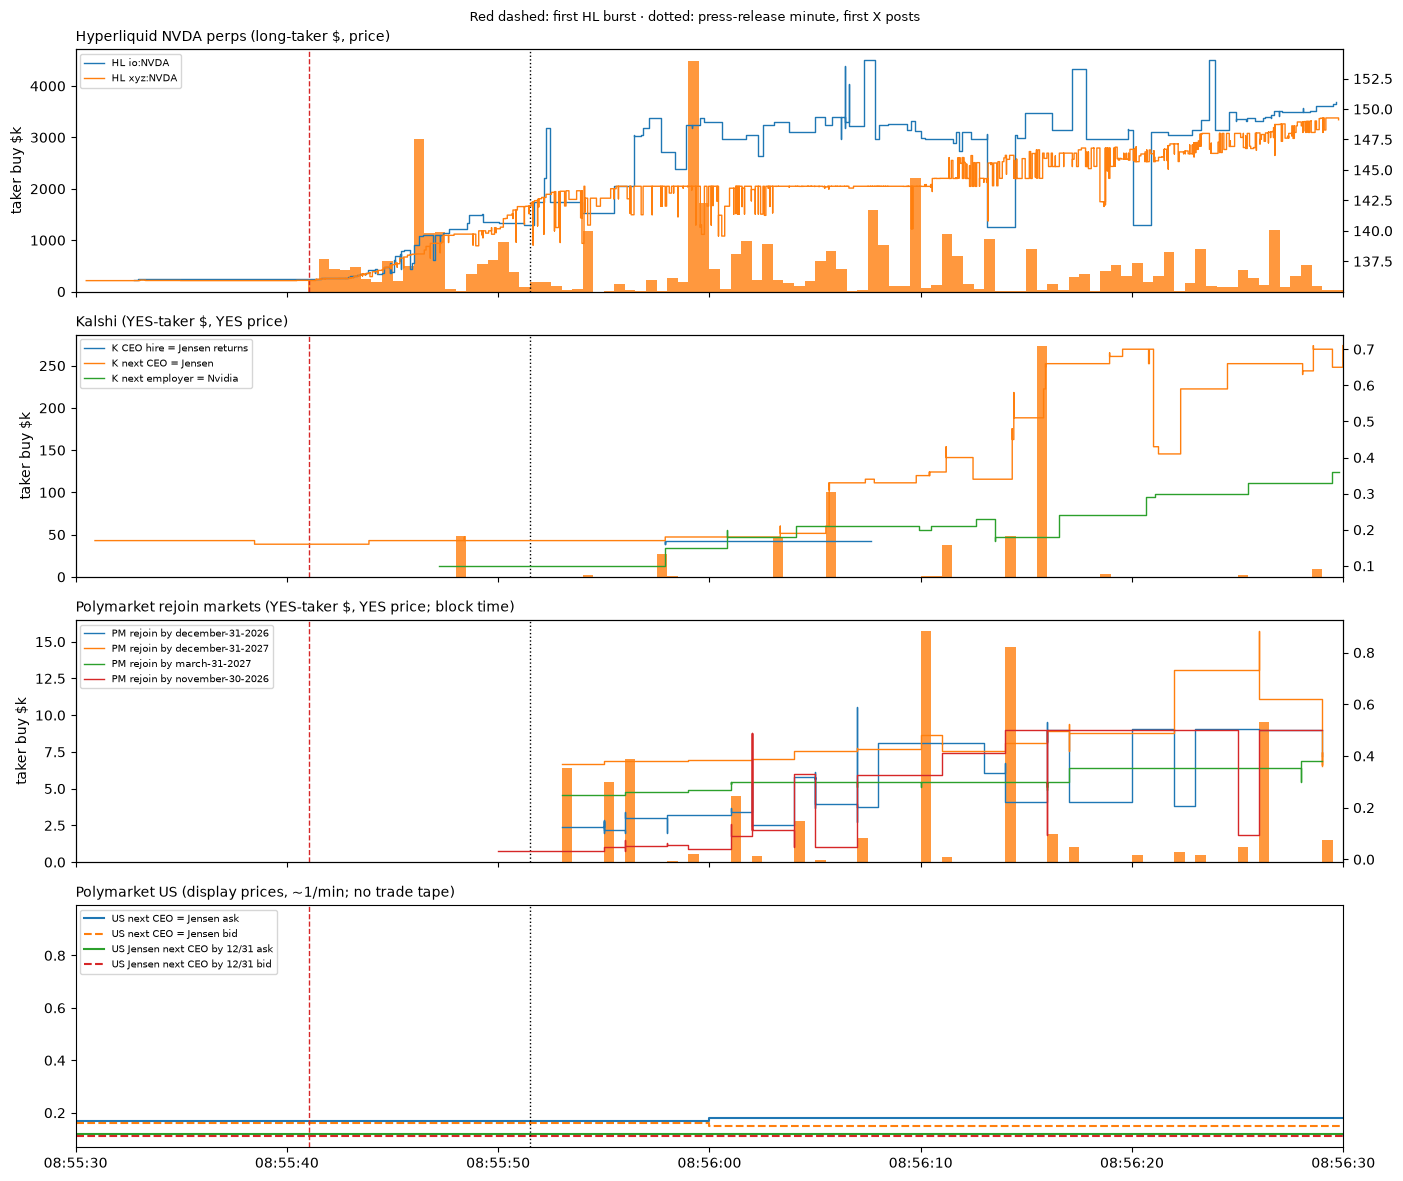

In [10]:
def chart(t0, t1, bucket_ms=500):
    groups = [("Hyperliquid NVDA perps (long-taker $, price)", tape.venue == "hyperliquid"),
              ("Kalshi (YES-taker $, YES price)", tape.venue == "kalshi"),
              ("Polymarket rejoin markets (YES-taker $, YES price; block time)", tape.venue == "polymarket")]
    fig, axes = plt.subplots(len(groups) + 1, 1, figsize=(14, 12), sharex=True)
    for ax, (title, mask) in zip(axes, groups):
        d = tape[mask & tape.t_ms.between(t0, t1)]
        flow = d[d.side > 0].assign(b=lambda x: pd.to_datetime(x.t_ms // bucket_ms * bucket_ms, unit="ms", utc=True).dt.tz_convert(ET)).groupby("b").usd.sum()
        ax.bar(flow.index, flow.values / 1e3, width=bucket_ms / 86_400_000, align="edge", color="tab:orange", alpha=.8)
        ax.set_ylabel("taker buy $k"); ax.set_title(title, loc="left", fontsize=10)
        px = ax.twinx()
        for lab, g in d.groupby("label"):
            px.step(g.time, g.price, where="post", lw=1, label=lab)
        px.legend(fontsize=7, loc="upper left")
    ax = axes[-1]
    for s, df in pmus.items():
        t = pd.to_datetime(df.t_ms, unit="ms", utc=True).dt.tz_convert(ET)
        ax.step(t, df.yes_ask, where="post", label=f"{PMUS[s]} ask"); ax.step(t, df.yes_bid, where="post", ls="--", label=f"{PMUS[s]} bid")
    ax.set_title("Polymarket US (display prices, ~1/min; no trade tape)", loc="left", fontsize=10); ax.legend(fontsize=7, loc="upper left")
    for a in axes:
        for name, m in MARKS.items():
            a.axvline(pd.Timestamp(m, unit="ms", tz="UTC").tz_convert(ET), color="k", ls=":", lw=1)
        a.axvline(pd.Timestamp(hl0, unit="ms", tz="UTC").tz_convert(ET), color="tab:red", ls="--", lw=1)
        a.set_xlim(pd.Timestamp(t0, unit="ms", tz="UTC").tz_convert(ET), pd.Timestamp(t1, unit="ms", tz="UTC").tz_convert(ET))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S", tz=ET))
    fig.suptitle("Red dashed: first HL burst · dotted: press-release minute, first X posts", fontsize=9)
    fig.tight_layout()
    return fig

chart(ms("2026-11-23T13:55:30Z"), ms("2026-11-23T13:56:30Z"));

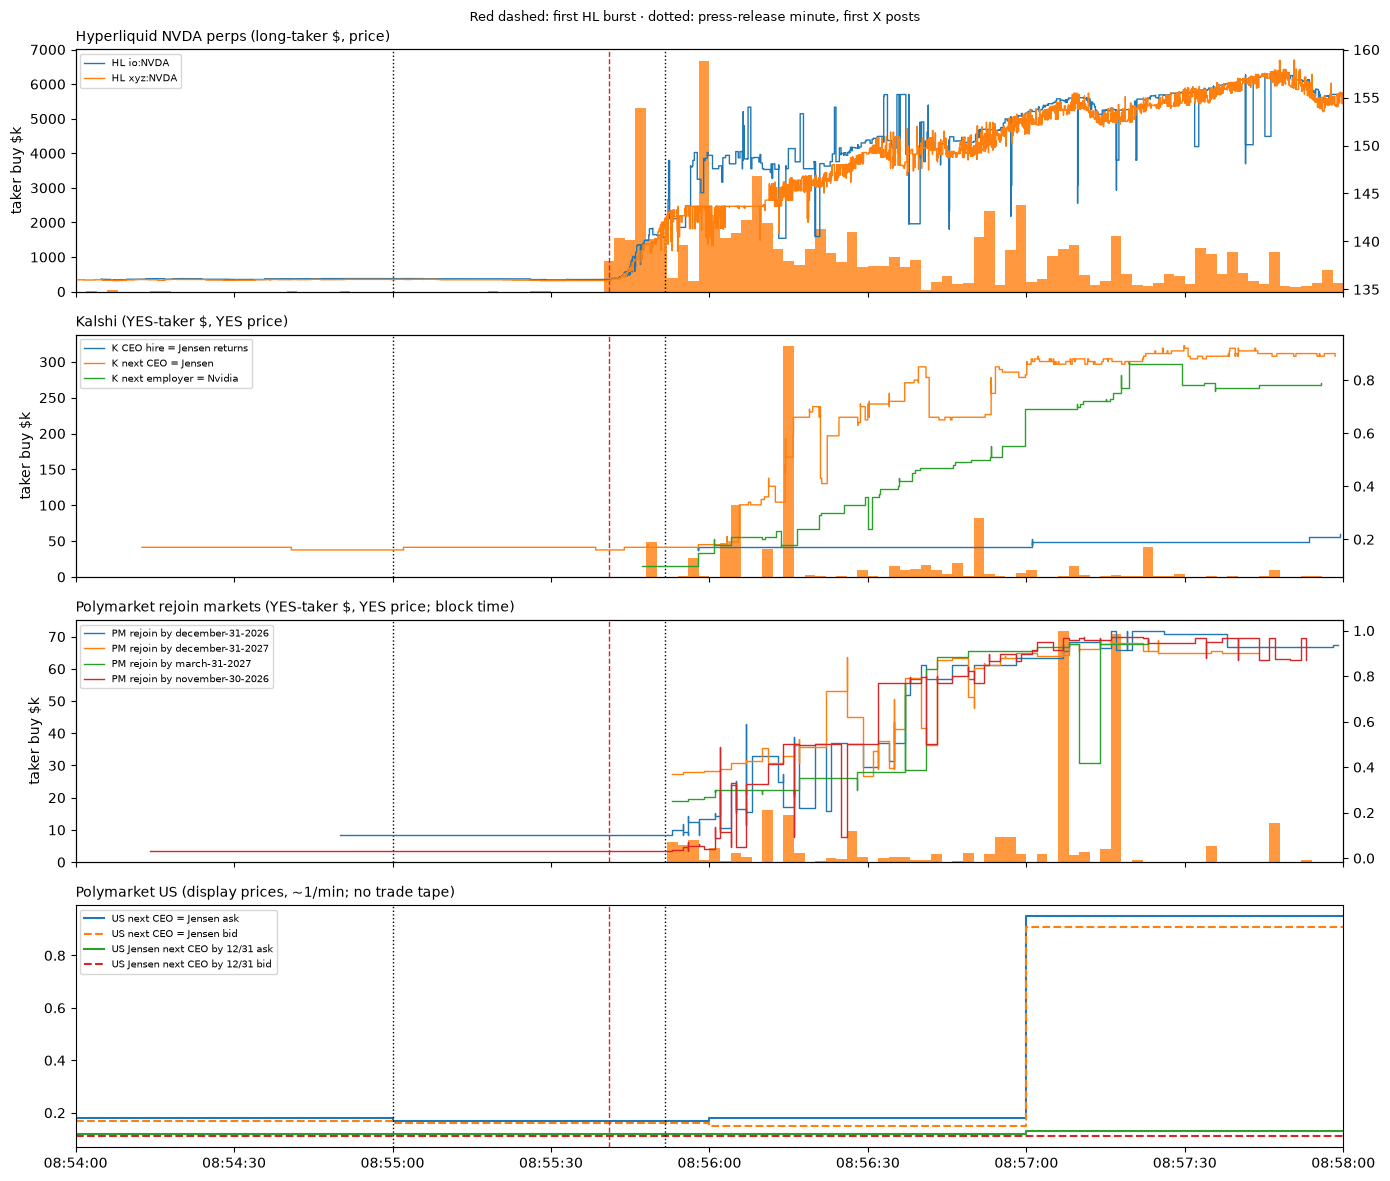

In [11]:
chart(START, END, bucket_ms=2000);

## 9. Was Hyperliquid the trigger?
One event can't separate two explanations: (a) prediction-market takers watch HL NVDA and react to it, or (b) everyone reads the same wire and HL's bots are simply fastest. Both predict HL first.

**What would separate them** (a set of past news events):
1. For each event, the gap between HL's first burst and Kalshi's or Polymarket's first burst. A tight, consistent gap supports (a).
2. HL bursts with no news (false signals). If prediction markets also jump on those, takers are trading HL itself.
3. News that prediction markets priced but HL didn't (no listed asset moved). This shows how much of the flow needs HL at all.

**Data needed for the set:** HL ticks further back than 24 h (Ironflow key: 14 days; AWS requester-pays S3: since Jul 2025), Kalshi (public, full history), Polymarket (public, full history). Polymarket US only from live capture going forward.